# DS-471 Project: Neural Network (Stages 3 & 4)
Breast Cancer Wisconsin (Diagnostic). This notebook builds, tunes and analyzes the **Neural Network** (MLP): baseline, 5-fold CV grid search, training/validation curves, over/underfitting analysis.

**Protocol (same as the rest of the report):** tuning with 5-fold stratified CV on the *training set only*; the validation set is only for monitoring; the test set is not touched here.

In [1]:
import numpy as np, pandas as pd, warnings, joblib
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)

## 1. Data: the group's `train.csv`, `val.csv`, `test.csv` from GitHub
Put the three files next to the notebook (in Colab: upload them, or `!git clone <repo>` and `%cd` into it). Every model in the project uses exactly these files. The scaler is fitted on the training set only (inside the Pipeline), so nothing leaks from validation or test.

In [2]:
TARGET = 'diagnosis'      # change if the target column has another name in the CSV files

tr, va, te = pd.read_csv('train.csv'), pd.read_csv('val.csv'), pd.read_csv('test.csv')
Xtr, ytr = tr.drop(columns=[TARGET]), tr[TARGET]
Xva, yva = va.drop(columns=[TARGET]), va[TARGET]
Xte, yte = te.drop(columns=[TARGET]), te[TARGET]      # test set: NOT used here, only in Stage 5

# if the target is stored as text, encode malignant = 1, benign = 0
if ytr.dtype == object:
    enc = {'M': 1, 'B': 0}; ytr, yva, yte = ytr.map(enc), yva.map(enc), yte.map(enc)

print(Xtr.shape, Xva.shape, Xte.shape, '| malignant %:', round(ytr.mean()*100,1), round(yva.mean()*100,1))
# sanity check: the files must be RAW (unscaled). Means far from 0 / std far from 1 = raw.
print(Xtr.describe().loc[['mean','std']].T.head(5).round(2))

(397, 20) (86, 20) (86, 20) | malignant %: 37.3 37.2
                        mean   std
smoothness_mean         0.10  0.01
compactness_mean        0.10  0.05
symmetry_mean           0.18  0.03
fractal_dimension_mean  0.06  0.01
radius_se               0.40  0.29


## 2. Baseline Neural Network (default settings)

In [3]:
def make_pipe(**kw):
    return Pipeline([('scaler', StandardScaler()),
                     ('mlp', MLPClassifier(solver='adam', random_state=42, **kw))])

def report(model, X, y):
    p, pr = model.predict(X), model.predict_proba(X)[:, 1]
    return dict(Accuracy=accuracy_score(y,p), Precision=precision_score(y,p), Recall=recall_score(y,p),
                F1=f1_score(y,p), ROC_AUC=roc_auc_score(y,pr))

base_kw = dict(hidden_layer_sizes=(100,), activation='relu', alpha=0.0001, learning_rate_init=0.001, max_iter=200)
base = make_pipe(**base_kw).fit(Xtr, ytr)
print(pd.DataFrame({'train': report(base, Xtr, ytr), 'validation': report(base, Xva, yva)}).T.round(3))
print('validation confusion matrix:\n', confusion_matrix(yva, base.predict(Xva)))

            Accuracy  Precision  Recall     F1  ROC_AUC
train          0.985      0.986   0.973  0.980    0.999
validation     0.965      0.939   0.969  0.954    0.997
validation confusion matrix:
 [[52  2]
 [ 1 31]]


## 3. Hyperparameter tuning (GridSearchCV, 5-fold stratified CV, training set only, scoring = F1 of malignant class)
700 combinations x 5 folds; may take a few minutes.

In [4]:
pipe = make_pipe()
grid = {'mlp__hidden_layer_sizes': [(8,), (16,), (32,), (16, 8), (32, 16)],
        'mlp__activation': ['relu', 'tanh'],
        'mlp__alpha': [0.0001, 0.001, 0.01, 0.1, 1.0],
        'mlp__learning_rate_init': [0.001, 0.01],
        'mlp__max_iter': [10, 20, 30, 50, 100, 200, 500]}      # epochs
cv = StratifiedKFold(5, shuffle=True, random_state=42)
gs = GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1, return_train_score=True, refit=False)
gs.fit(Xtr, ytr)

res = pd.DataFrame(gs.cv_results_)
res['gap'] = res.mean_train_score - res.mean_test_score
# best CV F1 (rounded to 3 decimals); ties are broken by the smallest train-validation gap
res['score3'] = res.mean_test_score.round(3)
res = res.sort_values(['score3', 'gap', 'mean_fit_time'], ascending=[False, True, True])
pd.set_option('display.max_colwidth', 200)
res[['params','mean_train_score','mean_test_score','std_test_score','gap']].head(8)

,params,mean_train_score,mean_test_score,std_test_score,gap
598,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.01, 'mlp__max_iter': 50}",0.979609,0.965118,0.016415,0.014491
388,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.01, 'mlp__max_iter': 50}",0.980453,0.965118,0.016415,0.015335
528,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.01, 'mlp__max_iter': 50}",0.980453,0.965118,0.016415,0.015335
458,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.01, 'mlp__max_iter': 50}",0.980453,0.965118,0.016415,0.015335
613,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (16, 8), 'mlp__learning_rate_init': 0.01, 'mlp__max_iter': 100}",0.999149,0.965013,0.025181,0.034136
664,"{'mlp__activation': 'tanh', 'mlp__alpha': 1.0, 'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.001, 'mlp__max_iter': 500}",0.970777,0.961615,0.017541,0.009161
440,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (16,), 'mlp__learning_rate_init': 0.001, 'mlp__max_iter': 500}",0.976118,0.961841,0.013960,0.014276
370,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (16,), 'mlp__learning_rate_init': 0.001, 'mlp__max_iter': 500}",0.976118,0.961841,0.013960,0.014276


In [5]:
best = {k.replace('mlp__',''): v for k, v in res.iloc[0].params.items()}
print('Selected hyperparameters:', best)
tuned = make_pipe(**best).fit(Xtr, ytr)
joblib.dump(tuned, 'nn_tuned.joblib')

for name, kw in [('baseline', base_kw), ('tuned', best)]:
    r = cross_validate(make_pipe(**kw), Xtr, ytr, cv=cv, scoring='f1', return_train_score=True)
    print(f"{name:9s} CV train F1 {r['train_score'].mean():.3f} +- {r['train_score'].std():.3f} | "
          f"CV val F1 {r['test_score'].mean():.3f} +- {r['test_score'].std():.3f}")

Selected hyperparameters: {'activation': 'tanh', 'alpha': 0.1, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.01, 'max_iter': 50}
baseline  CV train F1 0.985 +- 0.005 | CV val F1 0.951 +- 0.029
tuned     CV train F1 0.980 +- 0.003 | CV val F1 0.965 +- 0.016


## 4. Training / validation curves (per epoch)
The network is trained epoch by epoch with `partial_fit`; loss and accuracy are recorded on the training and validation sets after every epoch.

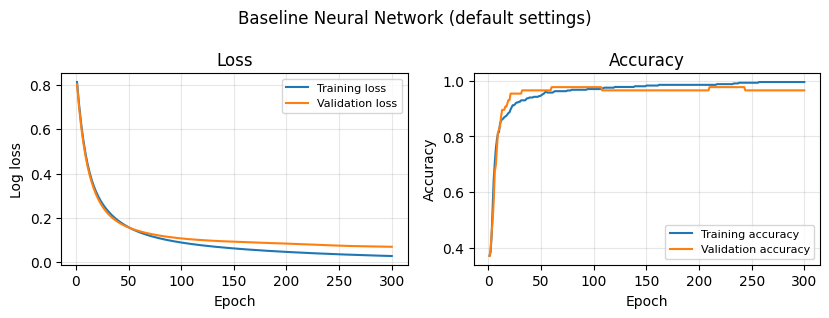

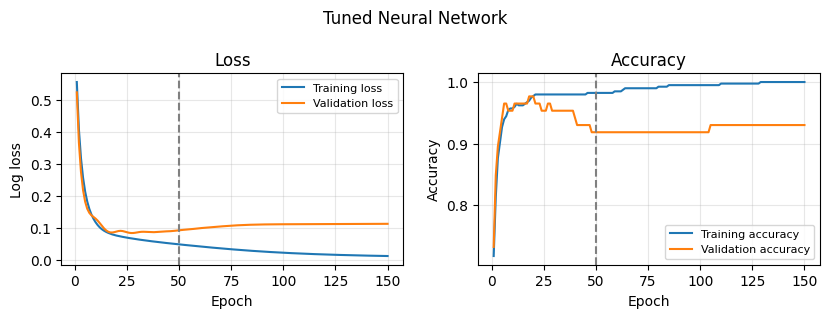

Tuned: min validation loss at epoch 27 0.0852


In [6]:
sc = StandardScaler().fit(Xtr)
A, B = sc.transform(Xtr), sc.transform(Xva)

def run(epochs, **kw):
    kw = {k: v for k, v in kw.items() if k != 'max_iter'}
    m = MLPClassifier(solver='adam', random_state=42, **kw)
    h = {k: [] for k in ['tl','vl','ta','va']}
    for _ in range(epochs):
        m.partial_fit(A, ytr, classes=[0, 1])
        pt, pv = m.predict_proba(A), m.predict_proba(B)
        h['tl'].append(log_loss(ytr, pt)); h['vl'].append(log_loss(yva, pv))
        h['ta'].append(accuracy_score(ytr, pt.argmax(1))); h['va'].append(accuracy_score(yva, pv.argmax(1)))
    return {k: np.array(v) for k, v in h.items()}

def plot_curves(h, title, mark=None, fname=None):
    ep = np.arange(1, len(h['tl']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.2))
    ax[0].plot(ep, h['tl'], label='Training loss'); ax[0].plot(ep, h['vl'], label='Validation loss')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Log loss'); ax[0].set_title('Loss')
    ax[1].plot(ep, h['ta'], label='Training accuracy'); ax[1].plot(ep, h['va'], label='Validation accuracy')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].set_title('Accuracy')
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8)
        if mark: a.axvline(mark, ls='--', color='gray')
    fig.suptitle(title); fig.tight_layout()
    if fname: fig.savefig(fname, dpi=200)
    plt.show()

h_base  = run(300, **base_kw)
h_tuned = run(150, **best)
plot_curves(h_base,  'Baseline Neural Network (default settings)', fname='fig_nn_baseline.png')
plot_curves(h_tuned, 'Tuned Neural Network', mark=best['max_iter'], fname='fig_nn_tuned.png')
print('Tuned: min validation loss at epoch', h_tuned['vl'].argmin()+1, round(h_tuned['vl'].min(), 4))

## 5. Validation curve for the number of epochs (over/underfitting)
Uses the CV results of the grid, with the other hyperparameters fixed at their selected values.

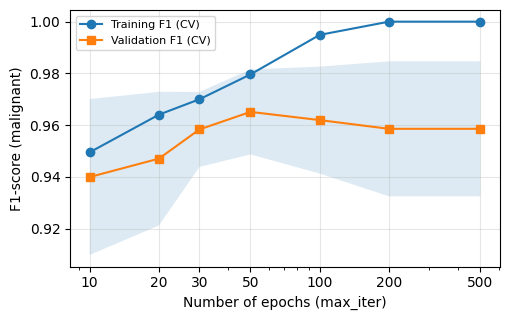

,epochs,mean_train_score,mean_test_score,std_test_score
595,10,0.9495,0.9400,0.0301
596,20,0.9641,0.9471,0.0258
597,30,0.9700,0.9583,0.0145
598,50,0.9796,0.9651,0.0164
599,100,0.9949,0.9620,0.0207
600,200,1.0000,0.9586,0.0261
601,500,1.0000,0.9586,0.0261


In [7]:
sel = res[res.params.apply(lambda p: all(p['mlp__'+k] == v for k, v in best.items() if k != 'max_iter'))].copy()
sel['epochs'] = sel.params.apply(lambda p: p['mlp__max_iter']); sel = sel.sort_values('epochs')
fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.plot(sel.epochs, sel.mean_train_score, 'o-', label='Training F1 (CV)')
ax.plot(sel.epochs, sel.mean_test_score, 's-', label='Validation F1 (CV)')
ax.fill_between(sel.epochs, sel.mean_test_score - sel.std_test_score, sel.mean_test_score + sel.std_test_score, alpha=.15)
ax.set_xscale('log'); ax.set_xticks(sel.epochs); ax.set_xticklabels(sel.epochs)
ax.set_xlabel('Number of epochs (max_iter)'); ax.set_ylabel('F1-score (malignant)'); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('fig_nn_valcurve.png', dpi=200); plt.show()
sel[['epochs','mean_train_score','mean_test_score','std_test_score']].round(4)

## 6. Training vs. validation performance

In [8]:
tab = pd.concat({'NN baseline': pd.DataFrame({'Training': report(base, Xtr, ytr), 'Validation': report(base, Xva, yva)}).T,
                 'NN tuned':    pd.DataFrame({'Training': report(tuned, Xtr, ytr), 'Validation': report(tuned, Xva, yva)}).T}).round(3)
print(tab)
print('Tuned validation confusion matrix:\n', confusion_matrix(yva, tuned.predict(Xva)))

                        Accuracy  Precision  Recall     F1  ROC_AUC
NN baseline Training       0.985      0.986   0.973  0.980    0.999
            Validation     0.965      0.939   0.969  0.954    0.997
NN tuned    Training       0.980      0.986   0.959  0.973    0.998
            Validation     0.942      0.909   0.938  0.923    0.993
Tuned validation confusion matrix:
 [[51  3]
 [ 2 30]]
